In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patches as patches
import matplotlib.cm as cm
import numpy as np

import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker
import cartopy.feature as feature
# import matplotlib.colors as colors
from cartopy.util import add_cyclic_point
from cartopy.mpl.ticker import (LongitudeFormatter, LatitudeFormatter)

In [2]:
# --- read mask

# input mask - Miocene
ds_mask = xr.open_dataset('../Miocene_LANDFRAC.nc')
var = 'LANDFRAC'
mask = ds_mask[var][0,:,:]
# Add cyclic point to mask
mask_Mio, lons = add_cyclic_point(mask, coord=ds_mask['lon'])

# ==================================================================
# input mask - Preindustrial
ds_mask = xr.open_dataset('../Preindustrial_LANDFRAC.nc')
var = 'LANDFRAC'
mask = ds_mask[var][0,:,:]
# Add cyclic point to mask
mask_Pi, lons = add_cyclic_point(mask, coord=ds_mask['lon'])

In [3]:
lat = ds_mask['lat']
lon = ds_mask['lon']
weights = np.cos(np.deg2rad(lat))

## Plant-Type patterns

In [4]:
# --- input Land Ice
# read data
file_ice = './FigS_LandIce.nc'
ds_ice = xr.open_dataset(file_ice)

# read variable: LandIce
ice_Pi = ds_ice['LandIce_Pi']
ice_Mio = ds_ice['LandIce_Mio']

# --- input Plant Function Type 
# read data
file_veg = './FigS_PFT.nc'
ds_veg = xr.open_dataset(file_veg)

# read variable: PCT_PFT
pft_Pi = ds_veg['PFT_Pi']
pft_Mio = ds_veg['PFT_Mio']


# --- compile the dataset
PFT_Pi = np.empty((18, lat.size, lon.size))
PFT_Pi = xr.DataArray(data=PFT_Pi, dims=['LandCover','lat','lon'], coords=[np.arange(1,18.5,1), lat, lon])
PFT_Mio = np.empty((18, lat.size, lon.size))
PFT_Mio = xr.DataArray(data=PFT_Mio, dims=['LandCover','lat','lon'], coords=[np.arange(1,18.5,1), lat, lon])

PFT_Pi[0:17,:,:] = pft_Pi
PFT_Pi[17,:,:] = ice_Pi
PFT_Mio[0:17,:,:] = pft_Mio
PFT_Mio[17,:,:] = ice_Mio

PFT_Pi = xr.DataArray(data=PFT_Pi, dims=['lsmpft','lat','lon'], coords=[np.arange(1,19,1), lat, lon])
PFT_Mio = xr.DataArray(data=PFT_Mio, dims=['lsmpft','lat','lon'], coords=[np.arange(1,19,1), lat, lon])

In [5]:
plant_type = ['Bare Ground','NL evergreen temperate','NL evergreen boreal','NL deciduous boreal',
              'BL evergreen tropical','BL evergreen temperate','BL deciduous tropical','BL deciduous temperate',
              'BL deciduous boreal','BL evergreen shrub','BL deciduous temperate shrub','BL deciduous boreal shrub',
              'arctic C3 grass','non-arctic C3 grass','C4 grass','corn','wheat','Land Ice [dark blue: > 5m]']

# Add cyclic point to mask
PFT_Pi, lons_veg = add_cyclic_point(PFT_Pi, coord=lon)
PFT_Mio, lons_veg = add_cyclic_point(PFT_Mio, coord=lon)

/glade/derecho/scratch/pjchen/tmp/ipykernel_39968/3345050621.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_veg = plt.cm.get_cmap('YlGn',len(levels_veg))
/glade/derecho/scratch/pjchen/tmp/ipykernel_39968/3345050621.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_ice = plt.cm.get_cmap('Blues',len(levels_ice))


''

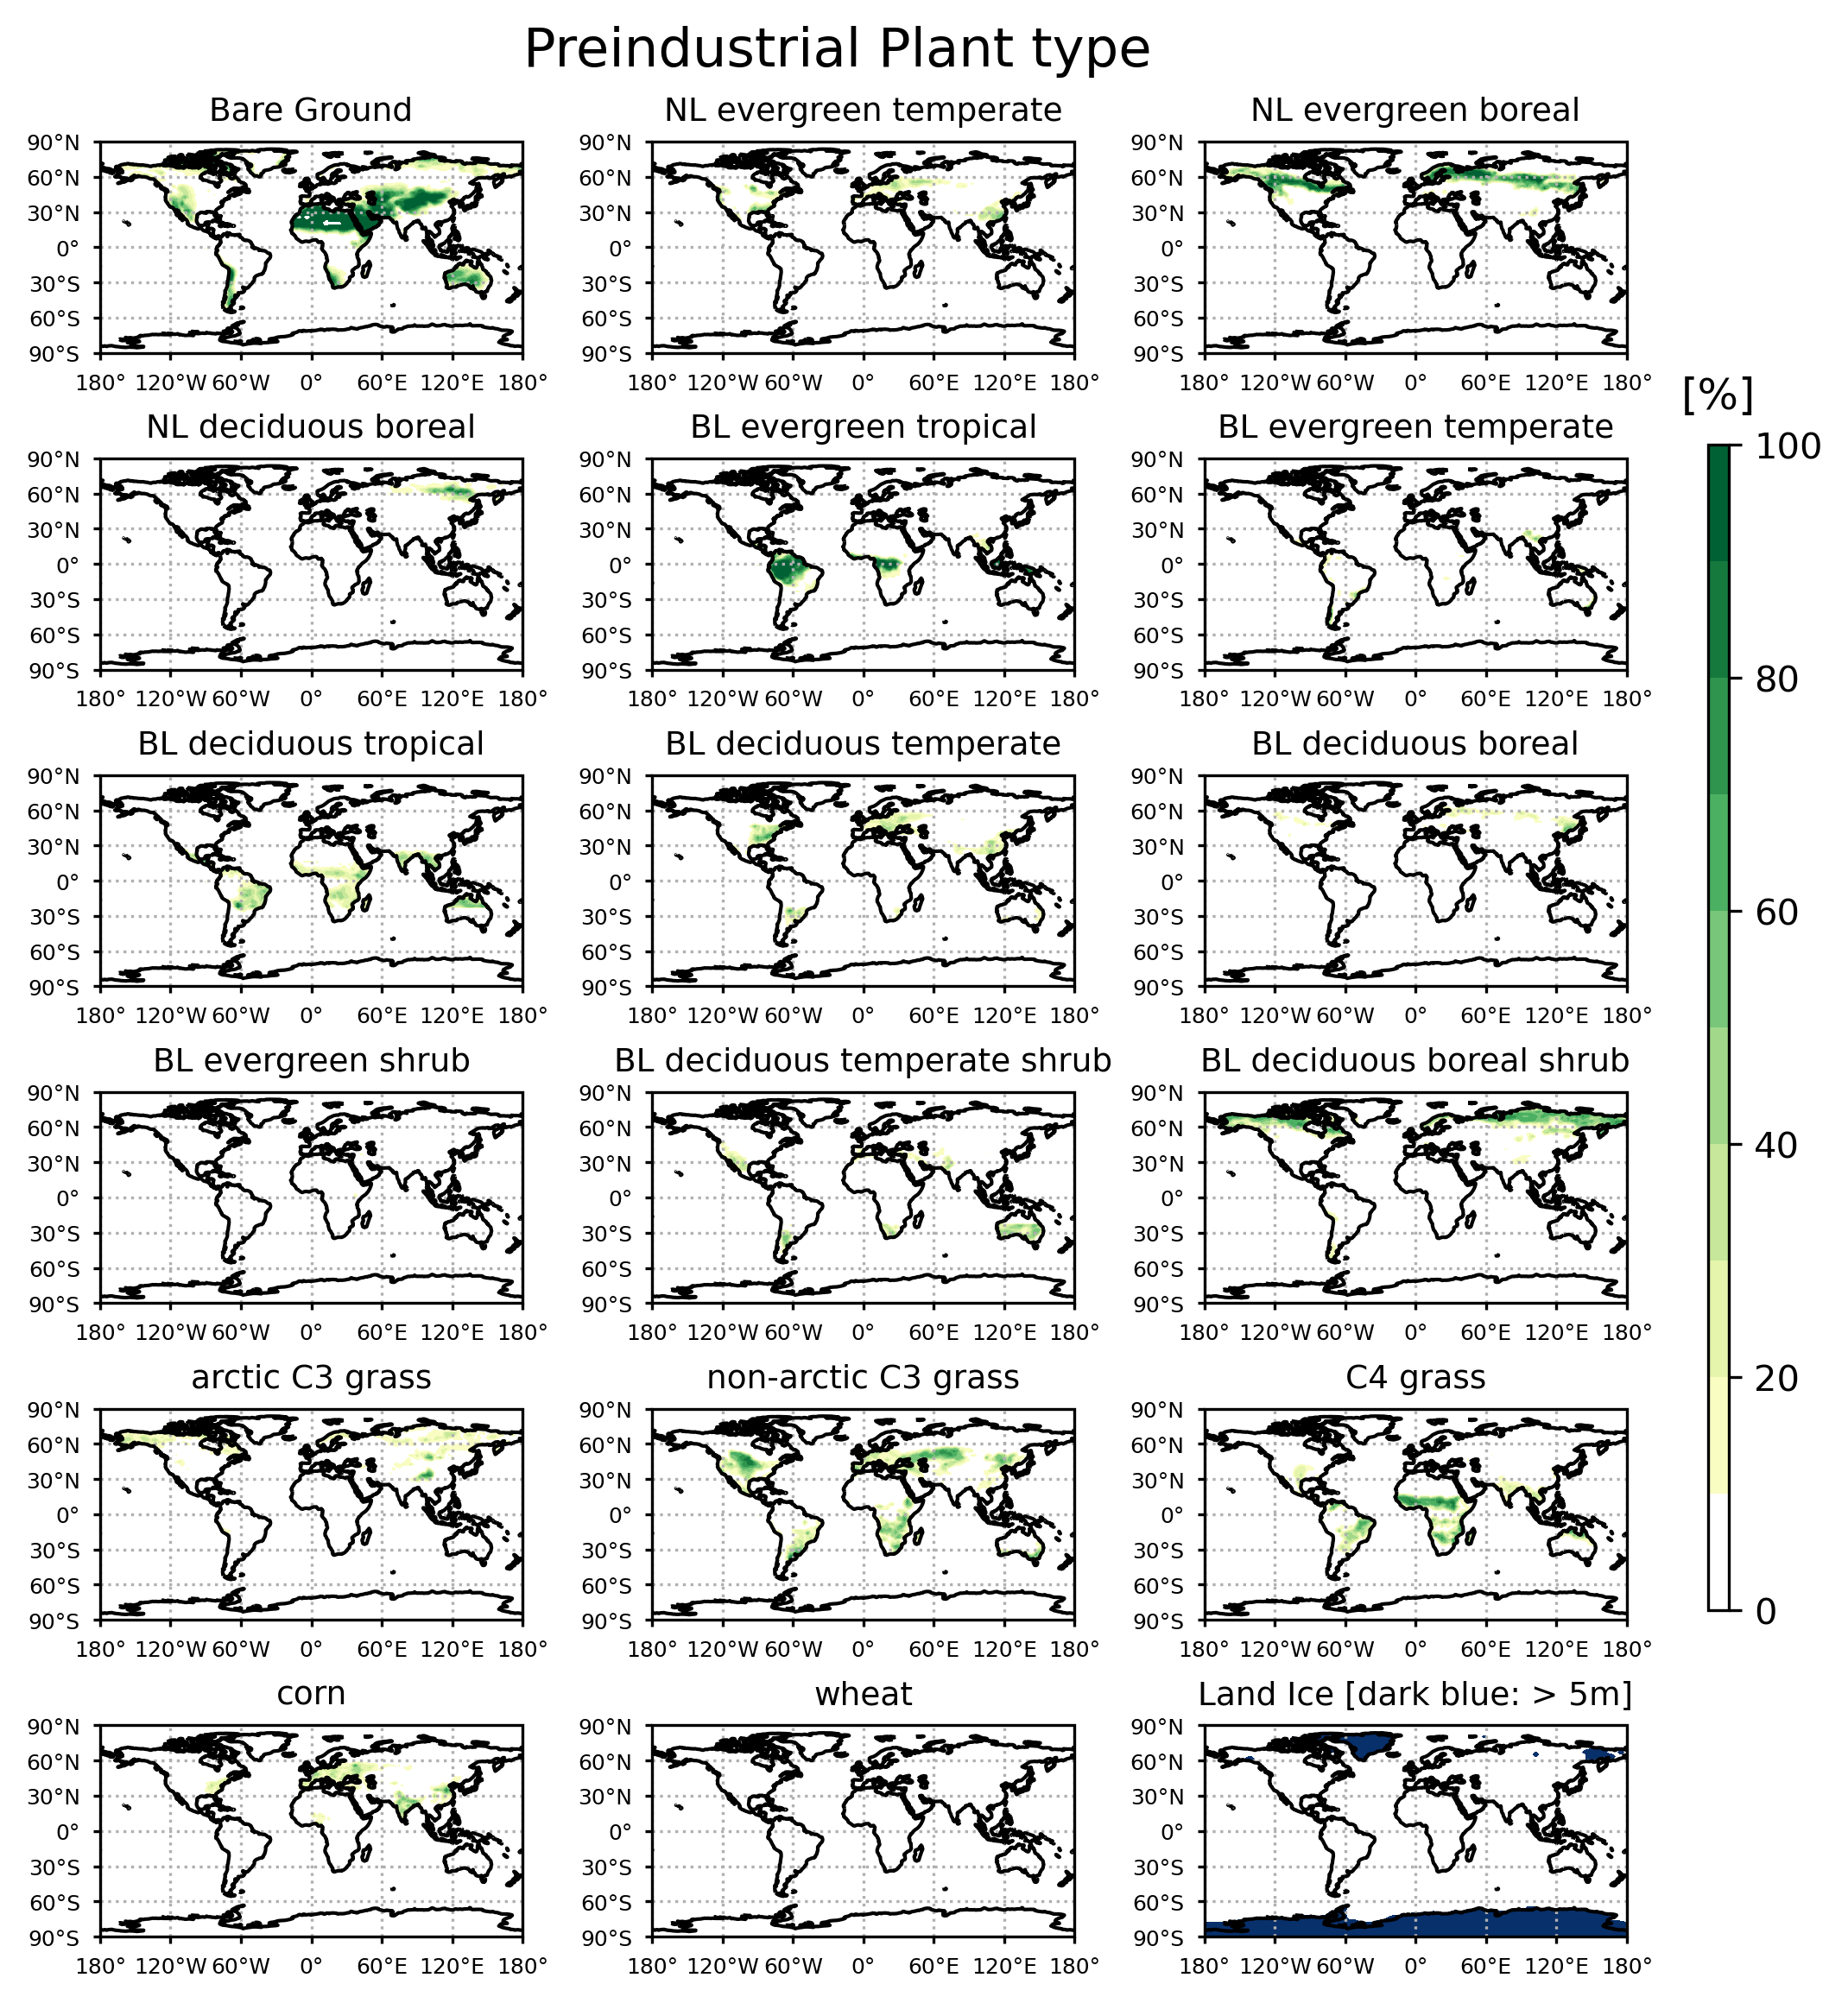

In [11]:
# --- Plotting ---

data_title = 'Preindustrial Plant type'
plot_name = 'plot_plant_type_PI'
levels_veg = np.arange(0,101,10)         # manually set the levels we want to see here
levels_ice = np.arange(0,1,0.1)          # manually set the levels we want to see here

cmap_veg = plt.cm.get_cmap('YlGn',len(levels_veg))
colors = list(cmap_veg(np.arange(len(levels_veg))))
colors[0] = "white"                                    #replace first color with white
cmap_veg = matplotlib.colors.ListedColormap(colors[:-1], "")
cmap_veg.set_over(colors[-1])                          # set over-color to last color of list 

cmap_ice = plt.cm.get_cmap('Blues',len(levels_ice))
colors = list(cmap_ice(np.arange(len(levels_ice))))
colors[0] = "white"                                    #replace first color with white
cmap_ice = mcolors.ListedColormap(colors[:-1], "")
cmap_ice.set_over(colors[-1])                          # set over-color to last color of list 


# Define the figure and each axis for the 6 rows and 3 columns
fig, axs = plt.subplots(nrows=6,ncols=3,
                        subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)},
                        figsize=(8,9), dpi=300)
    
# Set Width / Height padding between subplots, expressed as a fraction of the subplot width
fig.subplots_adjust(wspace=0.1, hspace=0.5) 
    
# flatten axs into a 1-D array
axs=axs.flatten()

# Loop over all of the types and plot
for i,m in enumerate(plant_type):
    
    if i==17:
        cs1=axs[i].contourf(lons_veg, lat, PFT_Pi[i,:,:], levels = levels_ice,
                           transform = ccrs.PlateCarree(), cmap=cmap_ice, extend='max')
    else:
        cs2=axs[i].contourf(lons_veg, lat, PFT_Pi[i,:,:], levels = levels_veg,
                           transform = ccrs.PlateCarree(), cmap=cmap_veg, extend='neither')
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,60), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()  
    axs[i].xaxis.set_major_formatter(lon_formatter)  # set the format of xticks_label
    axs[i].tick_params(axis='x', size=2)             # set xtick parameters
    for xlabel in axs[i].get_xticklabels():          # set xticks_label
        xlabel.set_fontsize(6)        

    # Latitude labels
    axs[i].set_yticks(np.arange(-90,91,30), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)  # set the format of yticks_label
    axs[i].tick_params(axis='y', size=2)             # set ytick parameters
    for ylabel in axs[i].get_yticklabels():          # set yticks_label
        ylabel.set_fontsize(6)        
    
    
    # Title each subplot with the name of the month
    axs[i].set_title(plant_type[i], fontsize=9)

    # Mask ocean
    cs_mask_ocean = axs[i].contourf(lons, lat, mask_Pi, [0.0,0.1],
                                    transform = ccrs.PlateCarree(), colors='white', zorder=2)
    
    # Add gridlines
    axs[i].gridlines(linestyle=':', zorder=2)
    
    axs[i].coastlines(zorder=3)     
        
# Add colorbar
cax  = fig.add_axes([0.92, 0.25, 0.01, 0.5])    # set the [x0, y0, width, height] of the colorbar
CB   = plt.colorbar(cs2, cax = cax)
CB.set_label('', rotation=0, fontsize=12)
CB.ax.set_title('[%]', fontsize=12, pad=10)

# Add title
plt.suptitle(data_title, y=0.93, fontsize=15)
# fig.savefig(plot_name+'.png')
;

/glade/derecho/scratch/pjchen/tmp/ipykernel_39968/43705602.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_veg = plt.cm.get_cmap('YlGn',len(levels_veg))
/glade/derecho/scratch/pjchen/tmp/ipykernel_39968/43705602.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_ice = plt.cm.get_cmap('Blues',len(levels_ice))


''

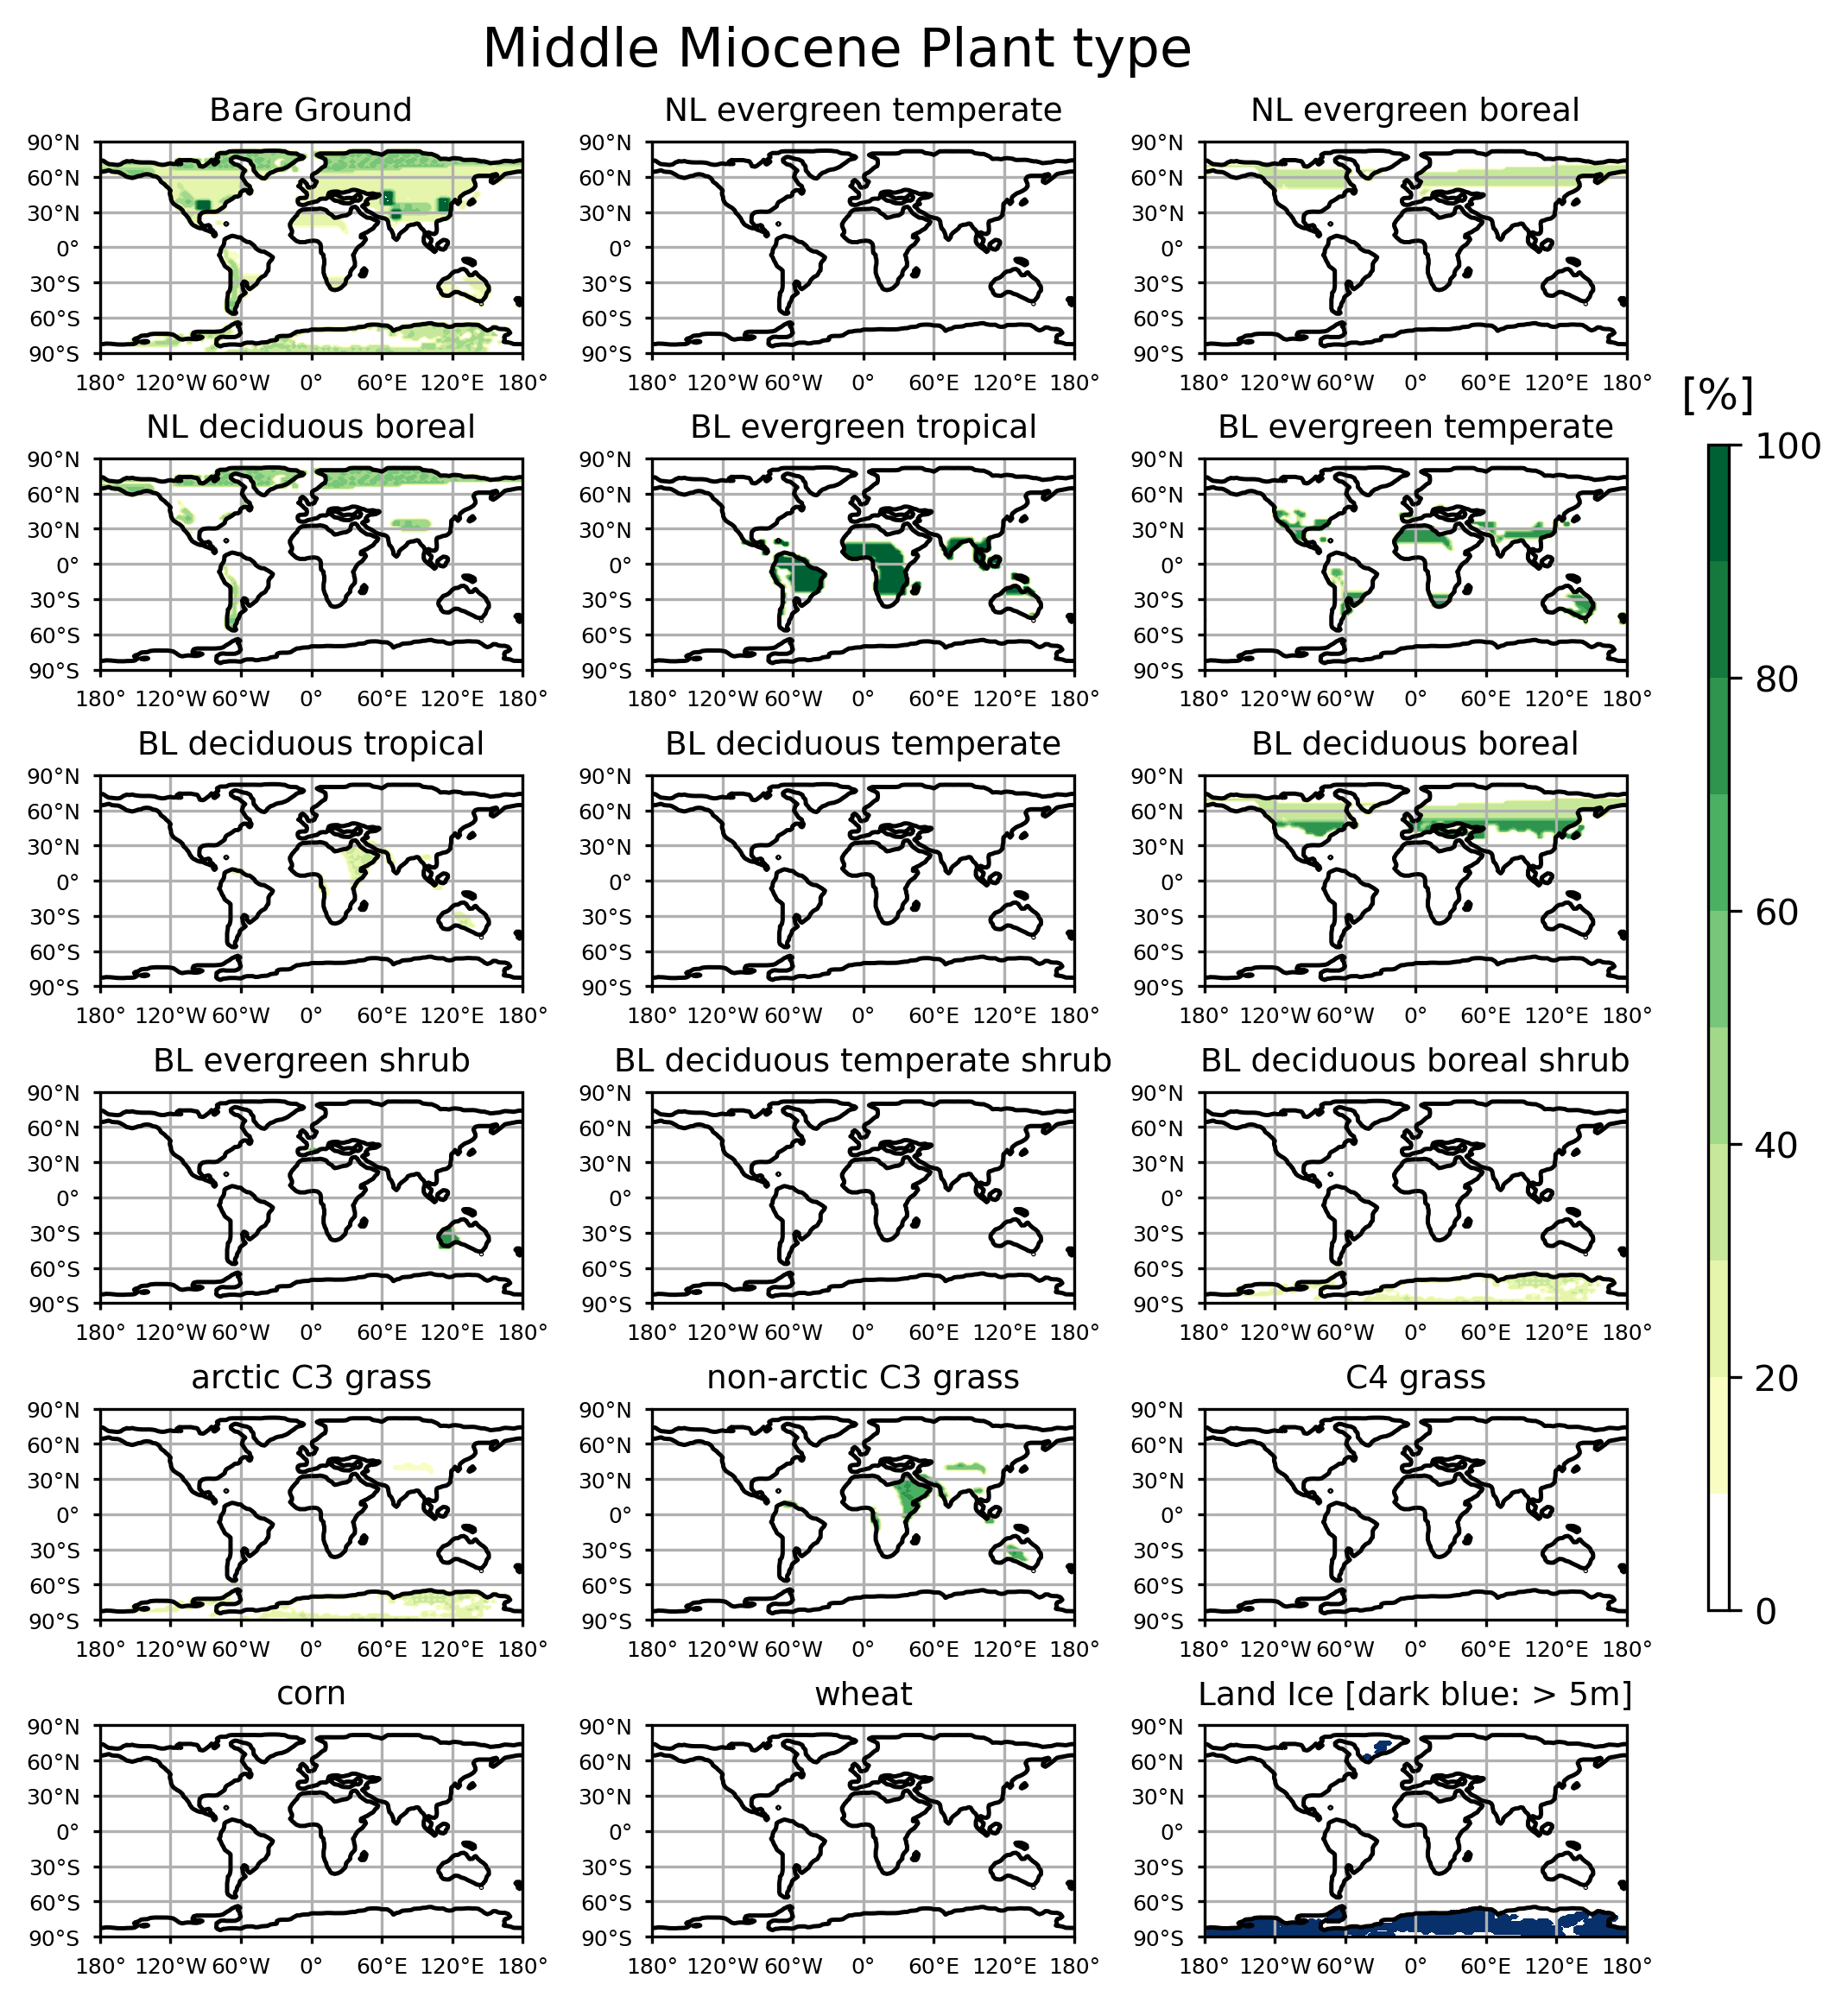

In [12]:
# --- Plotting ---

data_title = 'Middle Miocene Plant type'
plot_name = 'plot_plant_type_Miocene'
levels_veg = np.arange(0,101,10)         # manually set the levels we want to see here
levels_ice = np.arange(0,1,0.1)          # manually set the levels we want to see here

cmap_veg = plt.cm.get_cmap('YlGn',len(levels_veg))
colors = list(cmap_veg(np.arange(len(levels_veg))))
colors[0] = "white"                                    #replace first color with white
cmap_veg = matplotlib.colors.ListedColormap(colors[:-1], "")
cmap_veg.set_over(colors[-1])                          # set over-color to last color of list 

cmap_ice = plt.cm.get_cmap('Blues',len(levels_ice))
colors = list(cmap_ice(np.arange(len(levels_ice))))
colors[0] = "white"                                    #replace first color with white
cmap_ice = mcolors.ListedColormap(colors[:-1], "")
cmap_ice.set_over(colors[-1])                          # set over-color to last color of list 


# Define the figure and each axis for the 6 rows and 3 columns
fig, axs = plt.subplots(nrows=6,ncols=3,
                        subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)},
                        figsize=(8,9), dpi=300)
    
# Set Width / Height padding between subplots, expressed as a fraction of the subplot width
fig.subplots_adjust(wspace=0.1, hspace=0.5) 
    
# flatten axs into a 1-D array
axs=axs.flatten()

# Loop over all of the types and plot
for i,m in enumerate(plant_type):
    
    if i==17:
        # Contour plot
        cs1=axs[i].contourf(lons_veg, lat, PFT_Mio[i,:,:], levels = levels_ice,
                           transform = ccrs.PlateCarree(), cmap=cmap_ice, extend='max')
    else:
        cs2=axs[i].contourf(lons_veg, lat, PFT_Mio[i,:,:], levels = levels_veg,
                           transform = ccrs.PlateCarree(), cmap=cmap_veg, extend='neither')
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,60), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()  
    axs[i].xaxis.set_major_formatter(lon_formatter)  # set the format of xticks_label
    axs[i].tick_params(axis='x', size=2)             # set xtick parameters
    for xlabel in axs[i].get_xticklabels():          # set xticks_label
        xlabel.set_fontsize(6)        

    # Latitude labels
    axs[i].set_yticks(np.arange(-90,91,30), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)  # set the format of yticks_label
    axs[i].tick_params(axis='y', size=2)             # set ytick parameters
    for ylabel in axs[i].get_yticklabels():          # set yticks_label
        ylabel.set_fontsize(6)        
    
    
    # Title each subplot with the name of the month
    axs[i].set_title(plant_type[i], fontsize=9)
        
    # Add gridlines
    axs[i].gridlines(zorder=2)
    
    # Add coastlines: Miocene
    cs_mask = axs[i].contour(lons_veg, lat, mask_Mio, [0.3,1.5], transform = ccrs.PlateCarree(),
                             linestyles='solid', linewidths=1.2, colors='k', zorder=3)
     
        
# Add colorbar
cax  = fig.add_axes([0.92, 0.25, 0.01, 0.5])    # set the [x0, y0, width, height] of the colorbar
CB   = plt.colorbar(cs2, cax = cax)
CB.set_label('', rotation=0, fontsize=12)
CB.ax.set_title('[%]', fontsize=12, pad=10)

# Add title
plt.suptitle(data_title, y=0.93, fontsize=15)
# fig.savefig(plot_name+'.png')
;